# Your data: from spreadsheets to predictions, comparison and calibration

This notebook starts from **spreadsheets**, as a user with their own farms would:

| spreadsheet | one row per | columns |
|---|---|---|
| sites (`locais.csv`) | farm or station | name, latitude, longitude (decimal degrees, south and west negative), elevation (m) |
| weather (`clima_<farm>.csv`) | day | date, radiation (MJ/m²/d), Tmax and Tmin (°C), rain (mm); optional: humidity (%), wind (m/s at 2 m), dew point (°C) |
| soil (`solo.csv`) | layer | profile, top and bottom (cm), clay, sand, silt (%), organic carbon or matter (%), bulk density (g/cm³); optional: measured wilting point and field capacity (cm³/cm³) |
| seasons (`safras.csv`) | field × season | farm, field, sowing date, cultivar, maturity group, irrigated (sim/não); optional observations: yield (kg/ha), flowering and maturity (dates) |

Column names may be in English or Portuguese, with units in parentheses; common unit mistakes
(radiation in W/m², humidity as a fraction, texture in g/kg, organic matter instead of carbon) are
converted with a warning.

**The data here are synthetic.** Section 2 creates them with a simple generator (8 fictitious farms
in the Brazilian soybean belt, 1993-2024, 20 fields each) only to show the workflow with a large,
coherent data set. The "observations" are made with the emulator itself and a hidden cultivar, plus
noise, so that the calibration can be checked against a known answer. **To use your data, replace the
files in `my_data/` and skip section 2.**

1. the spreadsheet templates;
2. illustrative data (synthetic);
3. reading and checking the data;
4. predicting every season;
5. comparison with the observations;
6. calibration of the cultivars (and the check against the hidden truth);
7. using the calibrated cultivars: sowing window and climate scenarios per farm;
8. the same data with the AquaCrop emulator;
9. export.

In [1]:
try:
    import cropemu
    assert tuple(int(v) for v in cropemu.__version__.split(".")[:2]) >= (0, 3)
except (ImportError, AssertionError):     # install from PyPI (Intel Macs need --prefer-binary for rasterio)
    %pip install --quiet --prefer-binary "cropemu>=0.3"
    import cropemu

import time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cropemu.io import write_templates, read_sites, read_weather, read_soils, read_seasons
from cropemu.weather import check
from cropemu.weather.eto import extraterrestrial_radiation

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "0.9", "grid.linewidth": 0.6, "axes.edgecolor": "0.6",
                     "axes.titlesize": 10, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
                     "legend.fontsize": 8, "legend.frameon": False, "figure.dpi": 110,
                     "axes.prop_cycle": plt.cycler(color=SERIES)})
print("cropemu", cropemu.__version__)

cropemu 0.3.0


## 1. The spreadsheet templates

`write_templates` writes one example of each spreadsheet with the expected columns and units
(`lang="pt"` for Portuguese headers, `"en"` for English). Fill them in a spreadsheet program and
save as CSV (comma or semicolon; decimal point or comma), or read Excel files directly.

In [2]:
templates = write_templates("templates", lang="pt")
for p in templates:
    print(f"--- {p.name}")
    print(p.read_text())

--- locais.csv
fazenda,lat,lon,altitude (m)
A,-24.5,-51.6,600

--- clima.csv
data,radiacao (MJ/m2/d),tmax (C),tmin (C),chuva (mm),umidade (%),vento (m/s)
2023-10-01,22.5,31.2,18.4,0.0,65,2.1

--- solo.csv
perfil,topo (cm),base (cm),argila (%),areia (%),silte (%),carbono (%),densidade (g/cm3),pmp (cm3/cm3),cc (cm3/cm3)
A,0,20,55,25,20,1.6,1.2,,
A,20,60,60,20,20,0.9,1.25,,
A,60,200,62,18,20,0.4,1.3,,

--- safras.csv
fazenda,talhao,semeadura,cultivar,gm,irrigado,produtividade (kg/ha),florescimento,maturacao
A,T1,2023-10-15,minha cultivar,6.3,nao,3650,2023-12-10,2024-02-20



## 2. Illustrative data (synthetic)

*Skip this section with your own data.* A weather generator, simple but coherent:

- **rain:** wet or dry days from a two-state Markov chain (rain persists), with a wet-day
  probability and amount that follow the season; in the tropics the winter is dry, in the south
  the rain is spread over the year; amounts from a gamma distribution;
- **temperature:** mean annual temperature falling with latitude and elevation, a seasonal cycle
  growing with latitude, day-to-day anomalies that persist (AR(1)); wet days are cooler and have a
  smaller daily range;
- **radiation:** a fraction of the extraterrestrial radiation, lower on wet days;
- **humidity and wind:** higher humidity on wet days and in the rainy season; wind around 2 m/s.

Soils: clay, sand, organic carbon and density by layer, with clay increasing and carbon decreasing
with depth; one farm has measured water limits. Seasons: 20 fields per farm, one cultivar of two
per field and year, sowing spread over the farm's window, two irrigated fields.

In [3]:
rng = np.random.default_rng(2024)
DATA = Path("my_data"); DATA.mkdir(exist_ok=True)
FARMS = pd.DataFrame([
    # farm,        lat,    lon,  elev, clay %, sowing window starts
    ("Fazenda A", -12.6, -56.0, 380, 38, "10-01"),
    ("Fazenda B", -15.6, -54.3, 600, 48, "10-05"),
    ("Fazenda C", -17.8, -51.0, 750, 55, "10-10"),
    ("Fazenda D", -20.5, -54.8, 480, 26, "10-10"),
    ("Fazenda E", -23.3, -51.2, 600, 65, "10-01"),
    ("Fazenda F", -24.9, -53.4, 700, 70, "09-25"),
    ("Fazenda G", -28.3, -52.4, 680, 45, "10-20"),
    ("Fazenda H", -29.7, -55.5, 120, 20, "11-01"),
], columns=["fazenda", "lat", "lon", "altitude (m)", "clay", "window"])
FARMS[["fazenda", "lat", "lon", "altitude (m)"]].to_csv(DATA / "locais.csv", index=False)

def generate_weather(lat, elev, start="1993-01-01", end="2024-12-31", rng=rng):
    """Daily weather from a simple stochastic generator (illustration only)."""
    idx = pd.date_range(start, end)
    doy, n, a = idx.dayofyear.to_numpy(), len(idx), abs(lat)
    summer = np.cos(2 * np.pi * (doy - (15 if lat < 0 else 196)) / 365.25)        # +1 mid-summer
    tropical = np.clip((30 - a) / 15, 0, 1)                                        # 1 below 15°, 0 above 30°
    p_wet = np.clip(0.33 + 0.27 * tropical * summer, 0.03, 0.75)
    p11 = np.clip(p_wet + 0.25, 0, 0.95)                                           # persistence
    p01 = p_wet * (1 - p11) / (1 - p_wet)
    wet = np.zeros(n, bool)
    u = rng.random(n)
    for i in range(1, n):
        wet[i] = u[i] < (p11[i] if wet[i - 1] else p01[i])
    mean_amount = 11 + 5 * tropical * summer
    rain = np.where(wet, rng.gamma(0.75, mean_amount / 0.75), 0.0)
    anom = np.zeros(n)
    e = rng.normal(0, 1.4, n)
    for i in range(1, n):
        anom[i] = 0.75 * anom[i - 1] + e[i]
    tmean = 27.5 - 0.28 * max(a - 10, 0) - 0.0055 * elev + (0.6 + 0.25 * max(a - 10, 0)) * summer + anom - 0.8 * wet
    dtr = np.where(wet, 7.0, 11.0 + 2.5 * (1 - tropical * np.clip(summer, 0, 1))) + rng.normal(0, 1, n)
    ra = extraterrestrial_radiation(lat, doy)
    kt = np.clip(np.where(wet, 0.40, 0.62) + rng.normal(0, 0.06, n), 0.15, 0.78)
    rh = np.clip(np.where(wet, 86, 62 + 12 * tropical * summer - 8 * tropical * (summer < 0)) + rng.normal(0, 5, n), 25, 99)
    return pd.DataFrame({"data": idx.strftime("%Y-%m-%d"), "radiacao (MJ/m2/d)": np.round(kt * ra, 1),
                         "tmax (C)": np.round(tmean + dtr / 2, 1), "tmin (C)": np.round(tmean - dtr / 2, 1),
                         "chuva (mm)": np.round(rain, 1), "umidade (%)": np.round(rh, 0),
                         "vento (m/s)": np.round(rng.gamma(4, 0.5, n), 1)})

for f in FARMS.itertuples():
    w = generate_weather(f.lat, f._4)
    name = DATA / f"clima_{f.fazenda.split()[-1]}.csv"
    if f.fazenda == "Fazenda H":       # a station logger: radiation in W/m², dates day first, ';' and decimal ','
        w["radiacao (MJ/m2/d)"] = np.round(w["radiacao (MJ/m2/d)"] / 0.0864, 0)
        w = w.rename(columns={"radiacao (MJ/m2/d)": "radiacao (W/m2)"})
        w["data"] = pd.to_datetime(w["data"]).dt.strftime("%d/%m/%Y")
        w.to_csv(name, index=False, sep=";", decimal=",")
    else:
        w.to_csv(name, index=False)
print(sorted(p.name for p in DATA.iterdir()))

['clima_A.csv', 'clima_B.csv', 'clima_C.csv', 'clima_D.csv', 'clima_E.csv', 'clima_F.csv', 'clima_G.csv', 'clima_H.csv', 'locais.csv', 'safras.csv', 'solo.csv']


In [4]:
rows = []
LAYERS = [(0, 20), (20, 40), (40, 60), (60, 100), (100, 200)]
for f in FARMS.itertuples():
    for k, (top, bot) in enumerate(LAYERS):
        clay = min(f.clay + 4 * k + rng.normal(0, 2), 80)
        sand = max(100 - clay - (18 + rng.normal(0, 3)), 3) if f.clay > 30 else 100 - clay - 12
        soc = max(1.9 * np.exp(-k / 1.6) * (0.8 + f.clay / 150) + rng.normal(0, 0.05), 0.2)
        bd = 1.55 - 0.004 * clay + 0.03 * k + rng.normal(0, 0.02)
        row = {"perfil": f.fazenda, "topo (cm)": top, "base (cm)": bot, "argila (%)": round(clay, 1),
               "areia (%)": round(sand, 1), "silte (%)": round(100 - clay - sand, 1),
               "carbono (%)": round(soc, 2), "densidade (g/cm3)": round(bd, 2), "pmp (cm3/cm3)": None, "cc (cm3/cm3)": None}
        if f.fazenda == "Fazenda E":   # laboratory water limits for one farm
            row["pmp (cm3/cm3)"], row["cc (cm3/cm3)"] = round(0.27 + 0.01 * k, 3), round(0.40 + 0.005 * k, 3)
        rows.append(row)
pd.DataFrame(rows).to_csv(DATA / "solo.csv", index=False)
pd.read_csv(DATA / "solo.csv").head(7)

,perfil,topo (cm),base (cm),argila (%),areia (%),silte (%),carbono (%),densidade (g/cm3),pmp (cm3/cm3),cc (cm3/cm3)
0,Fazenda A,0,20,41.4,41.9,16.7,2.04,1.40,NaN,NaN
1,Fazenda A,20,40,39.5,45.6,14.9,1.05,1.42,NaN,NaN
2,Fazenda A,40,60,43.5,38.1,18.3,0.50,1.43,NaN,NaN
3,Fazenda A,60,100,49.4,29.4,21.1,0.32,1.44,NaN,NaN
4,Fazenda A,100,200,56.8,22.9,20.3,0.20,1.44,NaN,NaN
5,Fazenda B,0,20,44.3,38.0,17.7,2.10,1.36,NaN,NaN
6,Fazenda B,20,40,50.6,33.8,15.5,1.11,1.36,NaN,NaN


**Seasons and synthetic observations.** Each farm grows the two cultivars of the catalogue closest to
the typical maturity group of its latitude. The "true" cultivars of the farms are not the default
coefficients of their maturity group: they mature a little later and fill seeds longer (hidden
values below). The observed yield is the emulated yield of the true cultivar times a field effect
and a farm-year effect, plus measurement noise; the observed dates are emulated dates plus noise.
Some observations are missing, as in real records.

In [5]:
emu = cropemu.load("dssat-soybean-v1")
CATALOGUE = {"Cultivar 5.5": 5.5, "Cultivar 6.4": 6.4, "Cultivar 7.4": 7.4, "Cultivar 8.3": 8.3}
TRUE = {name: emu.cultivar(mg=mg + 0.4, LFMAX=1.10, SFDUR=24.5, SDPDV=2.2)   # hidden "true" cultivars
        for name, mg in CATALOGUE.items()}
YEARS = range(1994, 2024)                                     # sowing years (harvest the year after)
rows = []
for f in FARMS.itertuples():
    typ = emu.typical_mg(f.lat)
    names = sorted(CATALOGUE, key=lambda c: abs(CATALOGUE[c] - typ))[:2]
    for field in range(1, 21):
        for y in YEARS:
            start = pd.Timestamp(f"{y}-{f.window}")
            rows.append({"fazenda": f.fazenda, "talhao": f"T{field:02d}", "semeadura": start + pd.Timedelta(days=int(rng.integers(0, 50))),
                         "cultivar": names[int(rng.integers(0, 2))], "irrigado": "sim" if field <= 2 and f.fazenda == "Fazenda C" else "nao"})
plan = pd.DataFrame(rows)
plan["gm"] = plan["cultivar"].map(CATALOGUE)

# "observations": the emulator with the true cultivar (only to create synthetic data)
sites = FARMS.set_index("fazenda")
true_out = []
for (farm, cv, irr), g in plan.groupby(["fazenda", "cultivar", "irrigado"]):
    s = sites.loc[farm]
    w = read_weather(DATA / f"clima_{farm.split()[-1]}.csv", lat=s.lat, lon=s.lon, elev=s["altitude (m)"]) \
        if farm != "Fazenda H" else None
    if w is None:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            w = read_weather(DATA / "clima_H.csv", lat=s.lat, lon=s.lon, elev=s["altitude (m)"])
    soil = read_soils(DATA / "solo.csv")[farm]
    p = emu.predict(w, lat=s.lat, elev=s["altitude (m)"], soil=soil, sowing=list(g["semeadura"]),
                    cultivar=TRUE[cv], irrigated=irr == "sim").outputs
    true_out.append(p.set_index(g.index))
true_out = pd.concat(true_out).loc[plan.index]
field_eff = plan.groupby(["fazenda", "talhao"])["fazenda"].transform(lambda s: rng.normal(1, 0.06))
farm_year = plan.groupby(["fazenda", plan["semeadura"].dt.year])["fazenda"].transform(lambda s: rng.normal(1, 0.05))
plan["produtividade (kg/ha)"] = np.round(np.clip(true_out["HWAM"] * field_eff * farm_year + rng.normal(0, 150, len(plan)), 0, None), 0)
plan["florescimento"] = plan["semeadura"] + pd.to_timedelta(np.round(true_out["ADAT_dap"] + rng.normal(0, 2, len(plan))), unit="D")
plan["maturacao"] = plan["semeadura"] + pd.to_timedelta(np.round(true_out["MDAT_dap"] + rng.normal(0, 2.5, len(plan))), unit="D")
plan.loc[rng.random(len(plan)) < 0.6, "florescimento"] = pd.NaT          # flowering rarely recorded
plan.loc[rng.random(len(plan)) < 0.2, "maturacao"] = pd.NaT
plan.loc[rng.random(len(plan)) < 0.03, "produtividade (kg/ha)"] = np.nan
for c in ("semeadura", "florescimento", "maturacao"):
    plan[c] = plan[c].dt.strftime("%d/%m/%Y")
plan.drop(columns="gm").assign(gm=plan["gm"]).to_csv(DATA / "safras.csv", index=False)
print(len(plan), "seasons written;", pd.DataFrame(TRUE).T.loc[:, ["mg", "LFMAX", "SFDUR", "SDPDV"]].round(2).to_dict("index"))

4800 seasons written; {'Cultivar 5.5': {'mg': 5.9, 'LFMAX': 1.1, 'SFDUR': 24.5, 'SDPDV': 2.2}, 'Cultivar 6.4': {'mg': 6.8, 'LFMAX': 1.1, 'SFDUR': 24.5, 'SDPDV': 2.2}, 'Cultivar 7.4': {'mg': 7.8, 'LFMAX': 1.1, 'SFDUR': 24.5, 'SDPDV': 2.2}, 'Cultivar 8.3': {'mg': 8.7, 'LFMAX': 1.1, 'SFDUR': 24.5, 'SDPDV': 2.2}}


## 3. Reading and checking the data

From here on, the notebook only uses the files in `my_data/`: **this is where your data come in.**

In [6]:
sites = read_sites(DATA / "locais.csv")
soils = read_soils(DATA / "solo.csv")
seasons = read_seasons(DATA / "safras.csv")
weather = {}
for farm, s in sites.iterrows():
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        w = read_weather(DATA / f"clima_{farm.split()[-1]}.csv", lat=s["lat"], lon=s["lon"], elev=s["elev"])
    rep = check(w)
    weather[farm] = w
    print(f"{farm}: {w.index.min():%Y-%m-%d} to {w.index.max():%Y-%m-%d}, columns {list(w.columns)}, "
          f"missing days {rep['missing_days']}, out of range {rep['out_of_range']}"
          + (f", converted: {w.attrs['conversions']}" if w.attrs["conversions"] else ""))
print(f"soils: {list(soils)}; seasons: {len(seasons)} ({seasons['site'].nunique()} farms, "
      f"{seasons.groupby('site')['field'].nunique().sum()} fields, {seasons['sowing'].dt.year.nunique()} years)")
seasons.head()

Fazenda A: 1993-01-01 to 2024-12-31, columns ['srad', 'tmax', 'tmin', 'rain', 'rhum', 'wind'], missing days 0, out of range {}
Fazenda B: 1993-01-01 to 2024-12-31, columns ['srad', 'tmax', 'tmin', 'rain', 'rhum', 'wind'], missing days 0, out of range {}
Fazenda C: 1993-01-01 to 2024-12-31, columns ['srad', 'tmax', 'tmin', 'rain', 'rhum', 'wind'], missing days 0, out of range {}


Fazenda D: 1993-01-01 to 2024-12-31, columns ['srad', 'tmax', 'tmin', 'rain', 'rhum', 'wind'], missing days 0, out of range {}
Fazenda E: 1993-01-01 to 2024-12-31, columns ['srad', 'tmax', 'tmin', 'rain', 'rhum', 'wind'], missing days 0, out of range {}
Fazenda F: 1993-01-01 to 2024-12-31, columns ['srad', 'tmax', 'tmin', 'rain', 'rhum', 'wind'], missing days 0, out of range {}


Fazenda G: 1993-01-01 to 2024-12-31, columns ['srad', 'tmax', 'tmin', 'rain', 'rhum', 'wind'], missing days 0, out of range {}
Fazenda H: 1993-01-01 to 2024-12-31, columns ['srad', 'tmax', 'tmin', 'rain', 'rhum', 'wind'], missing days 0, out of range {}, converted: ['W/m² (daily mean) -> MJ/m²/d']
soils: ['Fazenda A', 'Fazenda B', 'Fazenda C', 'Fazenda D', 'Fazenda E', 'Fazenda F', 'Fazenda G', 'Fazenda H']; seasons: 4800 (8 farms, 160 fields, 30 years)


,site,field,sowing,cultivar,irrigated,obs_yield,obs_flowering,obs_maturity,mg
0,Fazenda A,T01,1994-10-02,Cultivar 8.3,False,5690.0,NaN,135.0,8.3
1,Fazenda A,T01,1995-10-01,Cultivar 8.3,False,6150.0,NaN,137.0,8.3
2,Fazenda A,T01,1996-10-26,Cultivar 7.4,False,1914.0,36.0,120.0,7.4
3,Fazenda A,T01,1997-10-21,Cultivar 8.3,False,6110.0,36.0,134.0,8.3
4,Fazenda A,T01,1998-11-12,Cultivar 8.3,False,5578.0,NaN,123.0,8.3


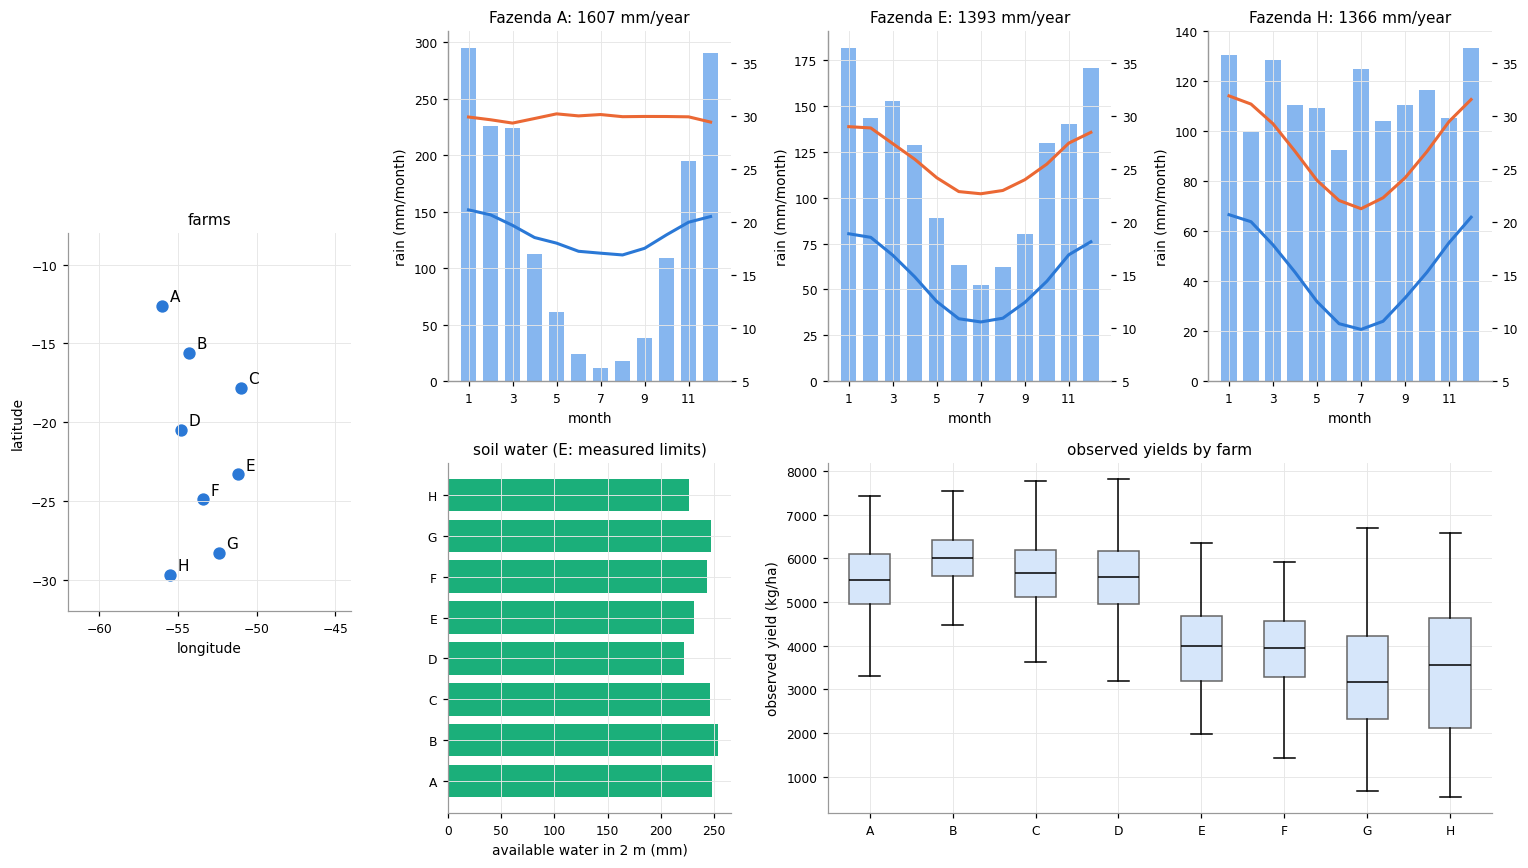

In [7]:
fig = plt.figure(figsize=(14, 8))
gs = fig.add_gridspec(2, 4)
ax = fig.add_subplot(gs[:, 0])
ax.scatter(sites["lon"], sites["lat"], s=50, color=SERIES[0])
for farm, s in sites.iterrows():
    ax.annotate(farm.split()[-1], (s["lon"], s["lat"]), xytext=(5, 3), textcoords="offset points")
ax.set(xlim=(-62, -44), ylim=(-32, -8), aspect="equal", xlabel="longitude", ylabel="latitude", title="farms")
for k, farm in enumerate(["Fazenda A", "Fazenda E", "Fazenda H"]):
    w = weather[farm]
    ax = fig.add_subplot(gs[0, k + 1])
    rain = w["rain"].groupby([w.index.year, w.index.month]).sum().groupby(level=1).mean()
    ax.bar(rain.index, rain, color="#86b6ef", width=0.7)
    ax2 = ax.twinx()
    m = w.groupby(w.index.month)[["tmax", "tmin"]].mean()
    ax2.plot(m.index, m["tmax"], color="#eb6834", lw=2); ax2.plot(m.index, m["tmin"], color="#2a78d6", lw=2)
    ax2.set_ylim(5, 38); ax2.grid(False)
    ax.set(title=f"{farm}: {w['rain'].resample('YS').sum().mean():.0f} mm/year", xlabel="month", ylabel="rain (mm/month)")
    ax.set_xticks(range(1, 13, 2))
ax = fig.add_subplot(gs[1, 1])
paw = {f: float(((p["dul"] - p["ll"]) * (p["bottom"] - p["top"]) * 10).sum()) if "dul" in p and p["dul"].notna().all()
       else float(cropemu.features.soil_features(emu.training_soil(p, sites.loc[f, "lat"]))["paw_mm"]) for f, p in soils.items()}
ax.barh([f.split()[-1] for f in paw], list(paw.values()), color=SERIES[2])
ax.set(xlabel="available water in 2 m (mm)", title="soil water (E: measured limits)")
ax = fig.add_subplot(gs[1, 2:])
order = list(sites.index)
ax.boxplot([seasons.loc[seasons["site"] == f, "obs_yield"].dropna() for f in order],
           showfliers=False, patch_artist=True, boxprops=dict(facecolor="#d6e6fa", color="0.4"), medianprops=dict(color="k"))
ax.set_xticks(range(1, len(order) + 1), [f.split()[-1] for f in order])
ax.set(ylabel="observed yield (kg/ha)", title="observed yields by farm")
fig.tight_layout(); plt.show()

## 4. Predicting every season

The cultivar of each season comes from its maturity group (`emu.cultivar(mg=...)`, the default
coefficients). The seasons of a farm, cultivar and water regime share one call; the inputs are kept
for the calibration (section 6).

In [8]:
def predict_all(emu, seasons, cultivars=None, family_out=("HWAM", "ADAT_dap", "MDAT_dap"), **kw):
    """Predict every season; returns (outputs, inputs, out-of-domain flags) aligned with ``seasons``."""
    outs, ins, ood = [], [], []
    for (farm, cv, irr), g in seasons.groupby(["site", "cultivar", "irrigated"]):
        s = sites.loc[farm]
        cult = cultivars[cv] if cultivars else emu.cultivar(mg=g["mg"].iloc[0])
        p = emu.predict(weather[farm], lat=s["lat"], elev=s["elev"], soil=soils[farm], sowing=list(g["sowing"]),
                        cultivar=cult, irrigated=bool(irr), **kw)
        outs.append(p.outputs[list(family_out)].set_axis(g.index)); ins.append(p.inputs.set_axis(g.index))
        ood.append(p.out_of_domain.set_axis(g.index))
    return pd.concat(outs).loc[seasons.index], pd.concat(ins).loc[seasons.index], pd.concat(ood).loc[seasons.index]

t0 = time.time()
pred, X, ood = predict_all(emu, seasons)
dt = time.time() - t0
seasons[["yield", "flowering", "maturity"]] = pred.to_numpy()
print(f"{len(seasons)} seasons in {dt:.1f} s ({1e3 * dt / len(seasons):.2f} ms per season, inputs from daily weather included)")
flag = ood.explode().dropna()
print("seasons with inputs out of the training domain:", int((ood.str.len() > 0).sum()),
      "| by farm and input:", flag.groupby([seasons.loc[flag.index, "site"], flag]).size().to_dict())
seasons[["site", "field", "sowing", "cultivar", "obs_yield", "yield", "obs_maturity", "maturity"]].head().round(0)

4800 seasons in 3.9 s (0.82 ms per season, inputs from daily weather included)
seasons with inputs out of the training domain: 1200 | by farm and input: {('Fazenda E', 'clay30'): 600, ('Fazenda F', 'clay30'): 600}


,site,field,sowing,cultivar,obs_yield,yield,obs_maturity,maturity
0,Fazenda A,T01,1994-10-02,Cultivar 8.3,5690.0,4783.0,135.0,129.0
1,Fazenda A,T01,1995-10-01,Cultivar 8.3,6150.0,5161.0,137.0,129.0
2,Fazenda A,T01,1996-10-26,Cultivar 7.4,1914.0,1688.0,120.0,115.0
3,Fazenda A,T01,1997-10-21,Cultivar 8.3,6110.0,5634.0,134.0,129.0
4,Fazenda A,T01,1998-11-12,Cultivar 8.3,5578.0,5049.0,123.0,121.0


The clay of the topsoil of farms E and F (65-75 %) is above the largest value of the training data
(65 %): their seasons are flagged, and their predictions are extrapolations. With your data, check
these flags first; the training range of every input is in `emu.card["domain"]`.

## 5. Comparison with the observations

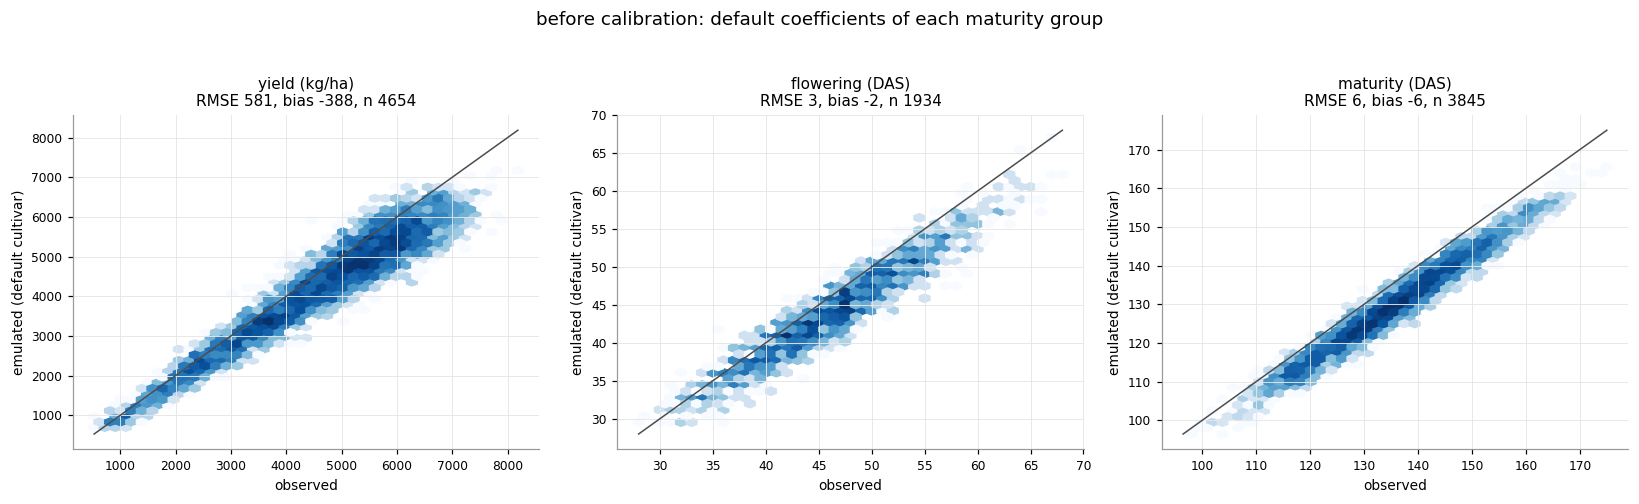

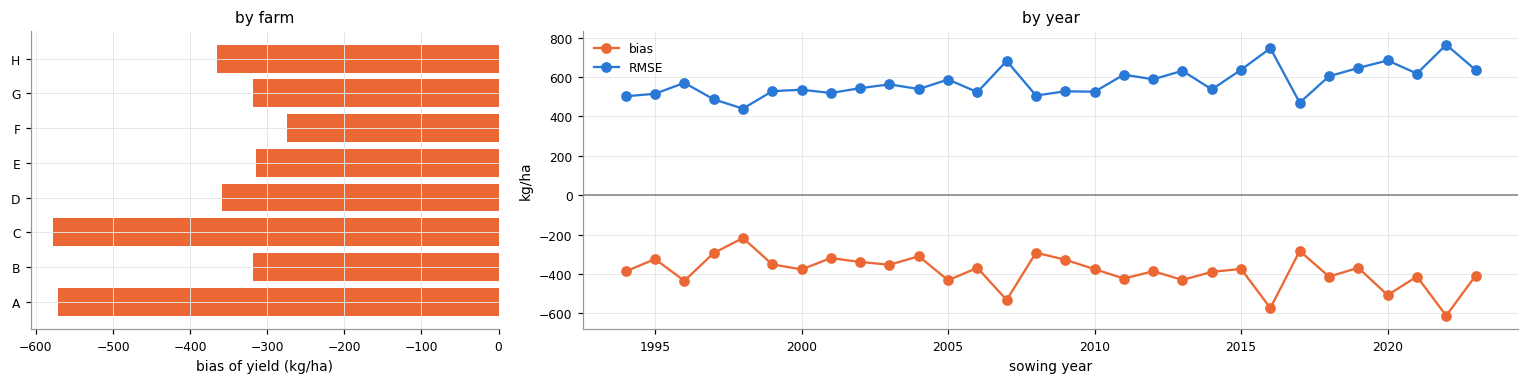

In [9]:
def scores(o, p):
    d = pd.concat([o, p], axis=1).dropna()
    e = d.iloc[:, 1] - d.iloc[:, 0]
    return pd.Series({"n": len(d), "RMSE": np.sqrt((e ** 2).mean()), "bias": e.mean(), "r": d.corr().iloc[0, 1]})

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, (o, p, lab) in zip(axes, [("obs_yield", "yield", "yield (kg/ha)"), ("obs_flowering", "flowering", "flowering (DAS)"),
                                   ("obs_maturity", "maturity", "maturity (DAS)")]):
    d = seasons[[o, p]].dropna()
    hb = ax.hexbin(d[o], d[p], gridsize=40, cmap="Blues", mincnt=1, bins="log")
    lim = [d.min().min(), d.max().max()]; ax.plot(lim, lim, color="0.3", lw=1)
    sc = scores(d[o], d[p])
    ax.set(xlabel="observed", ylabel="emulated (default cultivar)", title=f"{lab}\nRMSE {sc['RMSE']:.0f}, bias {sc['bias']:+.0f}, n {sc['n']:.0f}")
fig.suptitle("before calibration: default coefficients of each maturity group", y=1.03)
fig.tight_layout(); plt.show()

by_farm = seasons.groupby("site").apply(lambda g: scores(g["obs_yield"], g["yield"]), include_groups=False)
by_year = seasons.groupby(seasons["sowing"].dt.year).apply(lambda g: scores(g["obs_yield"], g["yield"]), include_groups=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6), gridspec_kw={"width_ratios": [1, 2]})
axes[0].barh([f.split()[-1] for f in by_farm.index], by_farm["bias"], color=SERIES[1])
axes[0].set(xlabel="bias of yield (kg/ha)", title="by farm")
axes[1].plot(by_year.index, by_year["bias"], marker="o", color=SERIES[1], label="bias"); axes[1].plot(by_year.index, by_year["RMSE"], marker="o", color=SERIES[0], label="RMSE")
axes[1].axhline(0, color="0.5", lw=1); axes[1].set(xlabel="sowing year", ylabel="kg/ha", title="by year"); axes[1].legend()
fig.tight_layout(); plt.show()

## 6. Calibration of the cultivars

Seasons sown in 1994-2013 calibrate, 2014-2023 evaluate. For each cultivar:

1. the maturity group (0.05 steps) that best reproduces the observed flowering and maturity dates;
2. then `LFMAX`, `SFDUR` and `SDPDV` on a grid inside their training range, against the observed yields.

The inputs of every season were computed once (section 4); a candidate cultivar only changes the
cultivar columns, so each candidate costs one call of the network for all its seasons.

In [10]:
cal = seasons["sowing"].dt.year <= 2013
d = emu.card["domain"]
grid_l = np.linspace(d["LFMAX"]["min"], d["LFMAX"]["max"], 6)
grid_s = np.linspace(d["SFDUR"]["min"], d["SFDUR"]["max"], 6)
grid_p = np.linspace(d["SDPDV"]["min"], d["SDPDV"]["max"], 6)
calibrated, curves = {}, {}
t0 = time.time(); n_eval = 0
for cv, g in seasons[cal].groupby("cultivar"):
    Xc = X.loc[g.index]
    mgs = np.round(np.arange(CATALOGUE[cv] - 1.5, CATALOGUE[cv] + 1.5001, 0.05), 2)
    P = emu.predict_inputs(pd.concat([Xc.assign(**emu.cultivar(mg=m)) for m in mgs], ignore_index=True)).outputs
    k = len(Xc)
    err = []
    for i in range(len(mgs)):
        e1 = P["ADAT_dap"].to_numpy()[i * k:(i + 1) * k] - g["obs_flowering"].to_numpy()
        e2 = P["MDAT_dap"].to_numpy()[i * k:(i + 1) * k] - g["obs_maturity"].to_numpy()
        err.append(np.sqrt(np.nanmean(np.concatenate([e1, e2]) ** 2)))
    mg = float(mgs[int(np.argmin(err))]); n_eval += len(mgs) * k
    combos = [(a, b, c) for a in grid_l for b in grid_s for c in grid_p]
    base = Xc.assign(**emu.cultivar(mg=mg))
    Y = emu.predict_inputs(pd.concat([base.assign(LFMAX=a, SFDUR=b, SDPDV=c) for a, b, c in combos],
                                     ignore_index=True)).outputs["HWAM"].to_numpy().reshape(len(combos), k)
    rmse = np.sqrt(np.nanmean((Y - g["obs_yield"].to_numpy()) ** 2, axis=1)); n_eval += len(combos) * k
    a, b, c = combos[int(np.argmin(rmse))]
    calibrated[cv] = emu.cultivar(mg=mg, LFMAX=a, SFDUR=b, SDPDV=c)
    curves[cv] = (mgs, np.array(err))
print(f"{n_eval:,} emulated seasons in {time.time() - t0:.1f} s")
cmp = pd.concat({"true (hidden)": pd.DataFrame(TRUE).T[["mg", "LFMAX", "SFDUR", "SDPDV"]],
                 "default": pd.DataFrame({c: emu.cultivar(mg=m) for c, m in CATALOGUE.items()}).T[["mg", "LFMAX", "SFDUR", "SDPDV"]],
                 "calibrated": pd.DataFrame(calibrated).T[["mg", "LFMAX", "SFDUR", "SDPDV"]]}, axis=1)
cmp.loc[sorted(calibrated)].round(2)

886,400 emulated seasons in 15.4 s


true (hidden)                   default                    \
                        mg LFMAX SFDUR SDPDV      mg LFMAX SFDUR SDPDV   
Cultivar 5.5           5.9   1.1  24.5   2.2     5.5  1.03  23.0  2.05   
Cultivar 6.4           6.8   1.1  24.5   2.2     6.4  1.03  23.0  2.05   
Cultivar 7.4           7.8   1.1  24.5   2.2     7.4  1.03  23.0  2.05   
Cultivar 8.3           8.7   1.1  24.5   2.2     8.3  1.03  23.0  2.05   

             calibrated                     
                     mg LFMAX  SFDUR SDPDV  
Cultivar 5.5        5.9  1.11  25.50  2.16  
Cultivar 6.4        6.8  1.11  23.12  2.16  
Cultivar 7.4        7.8  1.11  21.93  2.02  
Cultivar 8.3        8.7  1.07  24.31  1.74

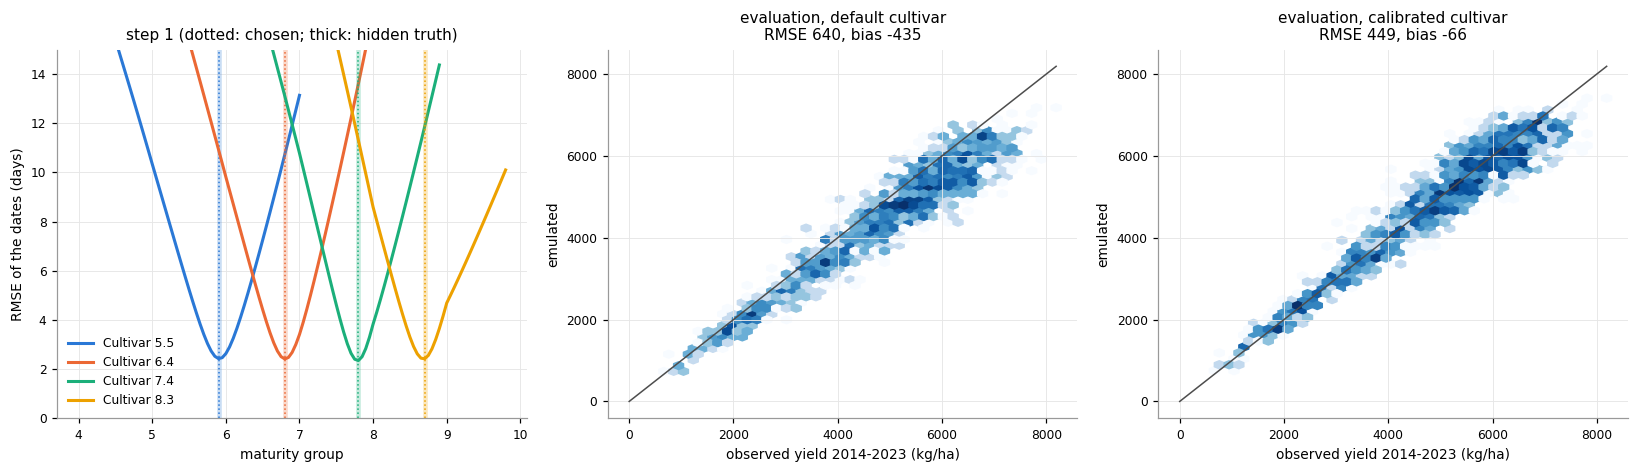

,default,calibrated
yield RMSE (kg/ha),640.2,448.7
flowering RMSE (d),3.0,2.0
maturity RMSE (d),6.4,2.5


In [11]:
pred_c, X_c, _ = predict_all(emu, seasons, cultivars={**{c: emu.cultivar(mg=m) for c, m in CATALOGUE.items()}, **calibrated})
seasons[["yield_cal", "flowering_cal", "maturity_cal"]] = pred_c.to_numpy()
ev = seasons[~cal]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
ax = axes[0]
for i, (cv, (m, e)) in enumerate(curves.items()):
    ax.plot(m, e, color=SERIES[i], lw=2, label=cv); ax.axvline(calibrated[cv]["mg"], color=SERIES[i], ls=":", lw=1)
    ax.axvline(TRUE[cv]["mg"], color=SERIES[i], lw=3, alpha=0.25)
ax.set(xlabel="maturity group", ylabel="RMSE of the dates (days)", title="step 1 (dotted: chosen; thick: hidden truth)", ylim=(0, 15)); ax.legend()
for ax, (p, lab) in zip(axes[1:], [("yield", "default cultivar"), ("yield_cal", "calibrated cultivar")]):
    d = ev[["obs_yield", p]].dropna()
    ax.hexbin(d["obs_yield"], d[p], gridsize=40, cmap="Blues", mincnt=1, bins="log")
    lim = [0, d.max().max()]; ax.plot(lim, lim, color="0.3", lw=1)
    sc = scores(d["obs_yield"], d[p])
    ax.set(xlabel="observed yield 2014-2023 (kg/ha)", ylabel="emulated", title=f"evaluation, {lab}\nRMSE {sc['RMSE']:.0f}, bias {sc['bias']:+.0f}")
fig.tight_layout(); plt.show()
pd.DataFrame({k: [scores(ev["obs_" + v], ev[v + s])["RMSE"] for v in ("yield", "flowering", "maturity")]
              for k, s in (("default", ""), ("calibrated", "_cal"))},
             index=["yield RMSE (kg/ha)", "flowering RMSE (d)", "maturity RMSE (d)"]).round(1)

The calibration recovers the hidden maturity group and moves the yield parameters towards the hidden
values; what remains is the noise added to the observations (field, farm-year and measurement
effects, ~300-400 kg/ha), which no cultivar can explain. With real data, part of the remaining error
is also the crop model itself.

## 7. Using the calibrated cultivars

**Sowing window per farm**: every 5 days from 15 September to 31 December, 1994-2023, rainfed, with
the calibrated cultivar the farm grows most.

5280 seasons in 4.0 s


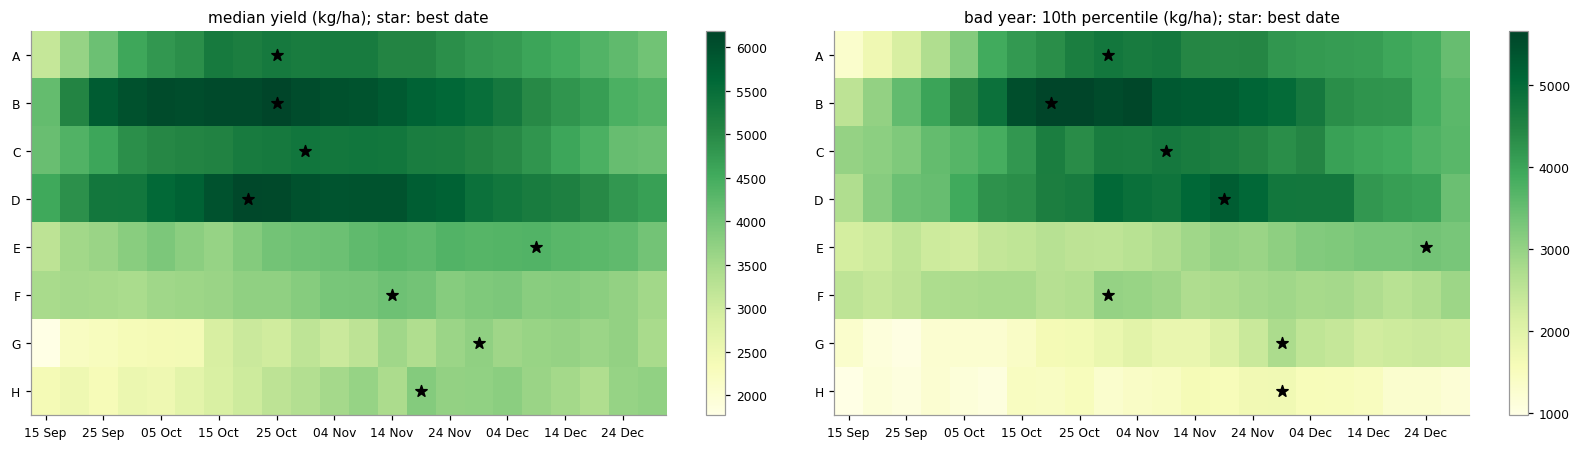

,cultivar,best date (median),median there (kg/ha),best date (bad years)
site,,,,
Fazenda A,Cultivar 7.4,25 Oct,5274.0,30 Oct
Fazenda B,Cultivar 7.4,25 Oct,6188.0,20 Oct
Fazenda C,Cultivar 7.4,30 Oct,5348.0,09 Nov
Fazenda D,Cultivar 7.4,20 Oct,6123.0,19 Nov
Fazenda E,Cultivar 7.4,09 Dec,4345.0,24 Dec
Fazenda F,Cultivar 5.5,14 Nov,4070.0,30 Oct
Fazenda G,Cultivar 6.4,29 Nov,3732.0,29 Nov
Fazenda H,Cultivar 6.4,19 Nov,3856.0,29 Nov


In [12]:
main = seasons.groupby("site")["cultivar"].agg(lambda s: s.value_counts().index[0])
offsets = np.arange(0, 107, 5)
rows = []
t0 = time.time()
for farm, cv in main.items():
    s = sites.loc[farm]
    dates = [pd.Timestamp(f"{y}-09-15") + pd.Timedelta(days=int(o)) for y in YEARS for o in offsets]
    p = emu.predict(weather[farm], lat=s["lat"], elev=s["elev"], soil=soils[farm], sowing=dates, cultivar=calibrated[cv])
    rows.append(pd.DataFrame({"site": farm, "offset": [o for _ in YEARS for o in offsets], "yield": p.outputs["HWAM"].to_numpy()}))
win = pd.concat(rows)
print(f"{len(win)} seasons in {time.time() - t0:.1f} s")
med = win.groupby(["site", "offset"])["yield"].median().unstack()
p10 = win.groupby(["site", "offset"])["yield"].quantile(0.1).unstack()
labels = [(pd.Timestamp("2001-09-15") + pd.Timedelta(days=int(o))).strftime("%d %b") for o in offsets]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
for ax, (tab, title) in zip(axes, [(med, "median yield (kg/ha)"), (p10, "bad year: 10th percentile (kg/ha)")]):
    im = ax.imshow(tab.to_numpy(), aspect="auto", cmap="YlGn")
    ax.set_yticks(range(len(tab)), [f.split()[-1] for f in tab.index]); ax.set_xticks(range(0, len(offsets), 2), labels[::2])
    best = tab.to_numpy().argmax(axis=1)
    ax.scatter(best, range(len(tab)), marker="*", color="k", s=60)
    plt.colorbar(im, ax=ax); ax.set(title=f"{title}; star: best date"); ax.grid(False)
fig.tight_layout(); plt.show()
pd.DataFrame({"cultivar": main, "best date (median)": [labels[i] for i in med.to_numpy().argmax(axis=1)],
              "median there (kg/ha)": med.max(axis=1).round(0),
              "best date (bad years)": [labels[i] for i in p10.to_numpy().argmax(axis=1)]})

**Climate scenarios per farm** (as in training: warming added to Tmax and Tmin, CO₂), with each farm's
seasons as recorded:

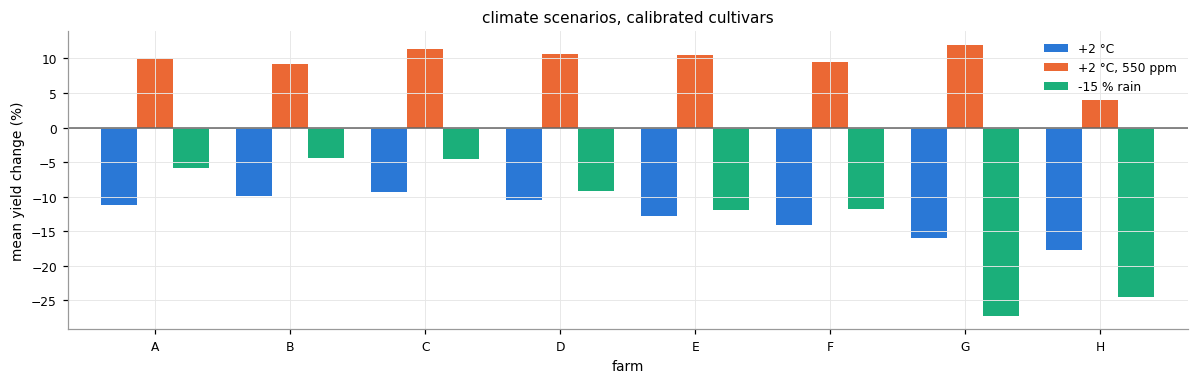

,+2 °C,"+2 °C, 550 ppm",-15 % rain
site,,,
Fazenda A,-11.2,9.9,-5.8
Fazenda B,-9.9,9.2,-4.5
Fazenda C,-9.3,11.3,-4.5
Fazenda D,-10.4,10.7,-9.2
Fazenda E,-12.8,10.5,-11.9
Fazenda F,-14.1,9.4,-11.8
Fazenda G,-16.0,12.0,-27.2
Fazenda H,-17.7,3.9,-24.4


In [13]:
scen = {"+2 °C": dict(dt=2.0), "+2 °C, 550 ppm": dict(dt=2.0, co2=550.0), "-15 % rain": dict(rain_factor=0.85)}
cultivars_cal = {**{c: emu.cultivar(mg=m) for c, m in CATALOGUE.items()}, **calibrated}
base = seasons.groupby("site")["yield_cal"].mean()
change = {}
for name, kw in scen.items():
    p, _, _ = predict_all(emu, seasons, cultivars=cultivars_cal, **kw)
    change[name] = 100 * (p["HWAM"].groupby(seasons["site"]).mean() / base - 1)
change = pd.DataFrame(change)
ax = change.rename(index=lambda f: f.split()[-1]).plot.bar(figsize=(11, 3.6), color=SERIES[:3], rot=0, width=0.8)
ax.axhline(0, color="0.4", lw=1); ax.set(ylabel="mean yield change (%)", xlabel="farm", title="climate scenarios, calibrated cultivars")
plt.tight_layout(); plt.show()
change.round(1)

## 8. The same data with the AquaCrop emulator

AquaCrop's cycle is a thermal time: for each cultivar it is the mean growing degrees between sowing
and the observed maturity of the calibration years (`cropemu.gdd_between`); the other crop
parameters keep the middle of their training range.

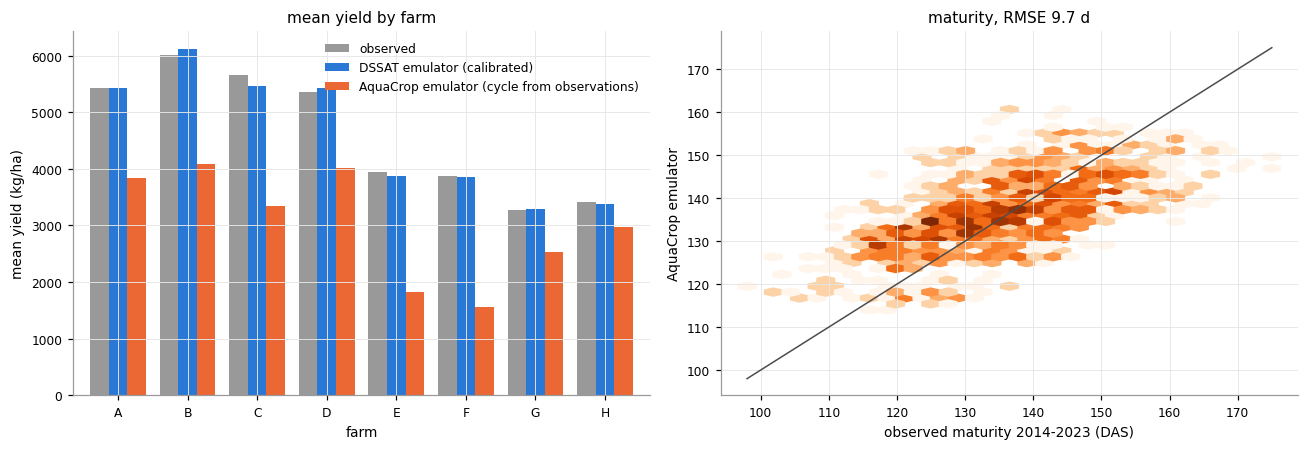

In [14]:
aq = cropemu.load("aquacrop-soybean-v1")
gdd = {}
for cv, g in seasons[cal & seasons["obs_maturity"].notna()].groupby("cultivar"):
    gdd[cv] = np.mean([cropemu.gdd_between(weather[r.site], r.sowing, r.sowing + pd.Timedelta(days=int(r.obs_maturity)))
                       for r in g.itertuples()])
aq_cult = {cv: aq.cultivar(gdd_maturity=v) for cv, v in gdd.items()}
p_aq, _, _ = predict_all(aq, seasons, cultivars=aq_cult, family_out=("Y(dry)", "FLO_dap", "MAT_dap"))
seasons["yield_aq"] = p_aq["Y(dry)"].to_numpy() * 1000
seasons["maturity_aq"] = p_aq["MAT_dap"].to_numpy()
ev = seasons[~cal]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
f = seasons.groupby("site")[["obs_yield", "yield_cal", "yield_aq"]].mean().rename(index=lambda x: x.split()[-1])
f.plot.bar(ax=axes[0], color=["0.6", SERIES[0], SERIES[1]], rot=0, width=0.8)
axes[0].legend(["observed", "DSSAT emulator (calibrated)", "AquaCrop emulator (cycle from observations)"])
axes[0].set(ylabel="mean yield (kg/ha)", xlabel="farm", title="mean yield by farm")
d = ev[["obs_maturity", "maturity_aq"]].dropna()
axes[1].hexbin(d["obs_maturity"], d["maturity_aq"], gridsize=30, cmap="Oranges", mincnt=1, bins="log")
lim = [d.min().min(), d.max().max()]; axes[1].plot(lim, lim, color="0.3", lw=1)
sc = scores(d["obs_maturity"], d["maturity_aq"])
axes[1].set(xlabel="observed maturity 2014-2023 (DAS)", ylabel="AquaCrop emulator", title=f"maturity, RMSE {sc['RMSE']:.1f} d")
fig.tight_layout(); plt.show()

The observations were created with the DSSAT emulator, so the AquaCrop emulator is not expected to
match them: the comparison shows how two crop models read the same farms differently, not which
one is right.

## 9. Export

In [15]:
out = Path("results"); out.mkdir(exist_ok=True)
seasons.assign(out_of_domain=ood.str.join(", ")).to_csv(out / "seasons_with_predictions.csv", index=False)
pd.DataFrame(calibrated).T.to_csv(out / "calibrated_cultivars.csv")
summary = seasons.groupby("site").agg(seasons=("sowing", "size"), obs_yield=("obs_yield", "mean"),
                                      yield_calibrated=("yield_cal", "mean"), yield_aquacrop=("yield_aq", "mean")).round(0)
summary.join(change.add_prefix("change % ").round(1)).to_csv(out / "farm_summary.csv")
print(sorted(p.name for p in out.iterdir()))
summary

['calibrated_cultivars.csv', 'farm_summary.csv', 'seasons_with_predictions.csv']


,seasons,obs_yield,yield_calibrated,yield_aquacrop
site,,,,
Fazenda A,600,5428.0,5430.0,3831.0
Fazenda B,600,6015.0,6128.0,4089.0
Fazenda C,600,5651.0,5470.0,3345.0
Fazenda D,600,5367.0,5427.0,4023.0
Fazenda E,600,3940.0,3867.0,1824.0
Fazenda F,600,3876.0,3851.0,1567.0
Fazenda G,600,3280.0,3284.0,2534.0
Fazenda H,600,3423.0,3382.0,2967.0
